#### readme  

&nbsp;&nbsp;&nbsp;&nbsp;-looks at a student's face (thru webcam) & outputs 4 numbers between 0 & 1 describing how the student seems to be feeling  
&nbsp;&nbsp;&nbsp;&nbsp;-Engagement, Boredom, Confusion, Frustration (0 = none, 1 = the maximum rating in DAiSEE)  
&nbsp;&nbsp;&nbsp;&nbsp;-final output for the GRU / LLM is a NumPy array of shape (T, 4), one row per time window, columns = `NAMES`  
  
```
video frame -> find the face -> crop it -> pretrained CNN ("backbone") -> 1280 numbers ("embedding")
                                                                                |
                                          small trainable "head" (the only part we train)
                                                                                |
                               4 scores between 0 & 1: Engagement, Boredom, Confusion, Frustration
```

&nbsp;&nbsp;&nbsp;&nbsp;-backbone -> a network someone else already trained on millions of photos (MobileNetV2)
&nbsp;&nbsp;&nbsp;&nbsp;-embedding -> the list of 1280 numbers the backbone uses to describe one picture  
&nbsp;&nbsp;&nbsp;&nbsp;-head -> a tiny network we train ourselves, reads an embedding & outputs the 4 scores  
&nbsp;&nbsp;&nbsp;&nbsp;-sigmoid -> a squashing function that turns any number to a value between 0 & 1  
&nbsp;&nbsp;&nbsp;&nbsp;-DAiSEE -> the dataset of student videos, each rated 0 to 3 for the 4 feelings (we divide by 3 to get 0 to 1 scores)  

which cells to run:  
&nbsp;&nbsp;&nbsp;&nbsp;-use a GPU runtime (Runtime > Change runtime type > T4 GPU) & run top to bottom  
&nbsp;&nbsp;&nbsp;&nbsp;-two switches in the settings cell control the slow one-time jobs (both False by default, so "Run all" can never retrain by accident)  

| situation | `RUN_EXTRACTION` | `RUN_TRAINING` | what happens |
|---|---|---|---|
| first time | True | True | saves embeddings & the trained head to Drive (VERY SLOW) |
| embeddings saved, want to retrain | False | True | trains in minutes from the saved embeddings |
| for normal runs | False | False | loads the saved head & goes straight to eval & webcam |

&nbsp;&nbsp;&nbsp;&nbsp;-results live on Drive (`FEAT_DIR`, `CKPT`, `METRICS_FILE`) so they save when colab closes, anything on colab's own disk (/content) is erased  
&nbsp;&nbsp;&nbsp;&nbsp;-`DEMO_MODE = True` skips Drive, extraction & training, the head is untrained, so the scores are placeholders that just prove the pipeline works (the accuracy metrics are skipped in that mode)  

#### CELL 1: Imports  
&nbsp;&nbsp;&nbsp;&nbsp;-every library the notebook needs is here
&nbsp;&nbsp;&nbsp;&nbsp;-before `import cv2` runs, a self-check makes sure OpenCV works  
&nbsp;&nbsp;&nbsp;&nbsp;-OpenCV 5 (the newest release) removed the face detector (`CascadeClassifier`), need OpenCV 4  
&nbsp;&nbsp;&nbsp;&nbsp;-if the check fails, the cell removes every OpenCV copy & installs OpenCV 4 automatically  
&nbsp;&nbsp;&nbsp;&nbsp;-if the cell then asks for a restart, do Runtime -> Restart session & run it again  

In [25]:
import os
import glob
import json
import time
import base64
import collections
import sys
import subprocess
import importlib

def opencv_works():
    try:
        import cv2
        return hasattr(cv2, 'CascadeClassifier')
    except ImportError:
        return False


if not opencv_works():
    print('OpenCV is missing, broken, or too new (OpenCV 5 has no face detector).')
    print('Installing OpenCV 4 (opencv-python-headless<5)...')
    subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', 'opencv-python', 'opencv-python-headless',
                    'opencv-contrib-python', 'opencv-contrib-python-headless'], check=False)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'opencv-python-headless<5'], check=True)
    for loaded in [name for name in sys.modules if name=='cv2' or name.startswith('cv2.')]:
        del sys.modules[loaded]
    importlib.invalidate_caches()
    if not opencv_works():
        raise RuntimeError('OpenCV 4 was installed, but this session still has the old copy loaded. '
                           'Go to Runtime > Restart session, then run this cell again (it will not reinstall).')
    print('OpenCV is ready.')

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as T
from google.colab import drive, output
from IPython.display import display, Javascript, JSON

#### CELL 2: Settings
&nbsp;&nbsp;&nbsp;&nbsp;-every adjustable number & option lives in this one cell, the rest of the notebook only reads them   
&nbsp;&nbsp;&nbsp;&nbsp;-the ones we'll edit most: `DEMO_MODE`, `RUN_EXTRACTION`, `RUN_TRAINING`, `CAMERA_INDEX`, `SAMPLE_VIDEO`  

In [26]:
DEMO_MODE = True
RUN_EXTRACTION = False
RUN_TRAINING = False

DAISEE_ROOT = '/content/drive/MyDrive/DAiSEE'
FEAT_DIR = '/content/drive/MyDrive/daisee_feats'
CKPT = '/content/drive/MyDrive/emotion_head.pt'
METRICS_FILE = '/content/drive/MyDrive/triaid_run_stats.json'
SPLITS = ['Train', 'Validation', 'Test']
SAMPLE_VIDEO = None
PLOT_DIR = None

NAMES = ['Engagement', 'Boredom', 'Confusion', 'Frustration']
MAX_RATING = 3

N_FRAMES = 16
FACE_SCALE_FACTOR = 1.2
FACE_MIN_NEIGHBORS = 5
FACE_MIN_SIZE_VIDEO = 60
FACE_MIN_SIZE_STREAM = 40
FACE_MARGIN = 0.15

CNN_INPUT_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
FEAT_DIM = 1280

HEAD_HIDDEN_SIZE = 256
HEAD_DROPOUT = 0.3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-2
BATCH_SIZE = 64
EPOCHS = 40
PRINT_EVERY = 5

VIDEO_WINDOW_S = 5.0
VIDEO_FRAMES_PER_WINDOW = 8

CAMERA_INDEX = 0
SEND_FPS = 15
SEND_WIDTH = 320
JPEG_QUALITY = 0.6
STREAM_WINDOW_S = 5.0
STREAM_MAX_FRAMES = 16
PREVIEW_WIDTH = 480
CAMERA_WIDTH = 640
CAMERA_HEIGHT = 480
CAMERA_FPS = 30
BAR_COLORS = ['#2e86de', '#8395a7', '#f39c12', '#e74c3c']
EXPORT_WINDOW_S = 5.0

HIGH_LEVEL = 2
METRIC_COLORS = ['#2e86de', '#f39c12', '#16a085', '#8e44ad', '#b2bec3']

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


#### CELL 3: Drive Connect  
&nbsp;&nbsp;&nbsp;&nbsp;-only needed when `DEMO_MODE` is False, b/c that's when we read the dataset & save files to drive  

In [27]:
if DEMO_MODE:
    print('DEMO_MODE is on: skipping Google Drive.')
else:
    drive.mount('/content/drive')
    os.makedirs(FEAT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### CELL 4: Stats Runner
&nbsp;&nbsp;&nbsp;&nbsp;-`STATS` collects the training numbers (epoch times, train loss, validation MAE) for our metrics section
&nbsp;&nbsp;&nbsp;&nbsp;-training only gets recorded when it runs, so `STATS` is saved to `METRICS_FILE` (on Drive) & loaded back in later sessions  
&nbsp;&nbsp;&nbsp;&nbsp;-`save_stats()` writes it & `load_stats()` reads it back (both functions don't work in `DEMO_MODE`)  

In [28]:
STATS = {
    'train_epoch_seconds': [],
    'train_loss': [],
    'val_mae': [],
}


def save_stats():
    if DEMO_MODE:
        return
    with open(METRICS_FILE, 'w') as stats_file:
        json.dump(STATS, stats_file)


def load_stats():
    if DEMO_MODE or not os.path.exists(METRICS_FILE):
        return
    with open(METRICS_FILE) as stats_file:
        STATS.update(json.load(stats_file))
    print(f"Loaded saved run statistics from {METRICS_FILE}")


load_stats()

#### SECTION 1A: Face Cropping  
&nbsp;&nbsp;&nbsp;&nbsp;-uses OpenCV's built-in face finder (a "Haar cascade", fast classic face detector)  
&nbsp;&nbsp;&nbsp;&nbsp;-`find_face` returns the biggest face as (x, y, w, h), or None if there isn't one  
&nbsp;&nbsp;&nbsp;&nbsp;-(x, y) is the top-left corner of the face box, w & h are its width & height in pixels  
&nbsp;&nbsp;&nbsp;&nbsp;-`crop_to_face` cuts the picture down to the face plus a small margin, if no face, then it returns the whole picture to prevent crashes  

In [29]:
face_detector = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
if face_detector.empty():
    raise RuntimeError('OpenCV could not load its face-detector file. Restart the session and run the imports cell again.')


def find_face(frame_bgr, min_size):
    gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)
    faces = face_detector.detectMultiScale(gray, FACE_SCALE_FACTOR, FACE_MIN_NEIGHBORS, minSize=(min_size, min_size))
    if len(faces)==0:
        return None
    return max(faces, key=lambda box: box[2]*box[3])


def crop_to_face(frame_bgr, face_box):
    if face_box is None:
        return frame_bgr
    x, y, w, h = face_box
    margin = int(FACE_MARGIN*w)
    top = max(y-margin, 0)
    left = max(x-margin, 0)
    return frame_bgr[top:y+h+margin, left:x+w+margin]

#### SECTION 1B: Backbone (face- > 1280 nums)  
&nbsp;&nbsp;&nbsp;&nbsp;-MobileNetV2 w/ weights already trained on ImageNet which uses millions of photos
&nbsp;&nbsp;&nbsp;&nbsp;-`preprocess` resizes & normalises pictures
&nbsp;&nbsp;&nbsp;&nbsp;-`embed_frames` takes a list of video frames, finds & crops the face in each, & returns one embedding per frame  
&nbsp;&nbsp;&nbsp;&nbsp;-`@torch.no_grad()` tells PyTorch "we're not training here", saves memory & time by disabling gradient calcs

In [30]:
_feature_layers = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT).features

backbone = nn.Sequential(_feature_layers, nn.AdaptiveAvgPool2d(1), nn.Flatten())
backbone = backbone.to(device).eval()

preprocess = T.Compose([
    T.ToPILImage(),
    T.Resize((CNN_INPUT_SIZE, CNN_INPUT_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def prepare_for_cnn(face_bgr):
    face_rgb = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2RGB)
    return preprocess(face_rgb)


@torch.no_grad()
def embed_frames(frames_bgr):
    prepared = []
    for frame in frames_bgr:
        face_box = find_face(frame, FACE_MIN_SIZE_VIDEO)
        prepared.append(prepare_for_cnn(crop_to_face(frame, face_box)))
    batch = torch.stack(prepared).to(device)
    return backbone(batch).cpu().numpy()

#### SECTION 1C: Read Frames from Video  

&nbsp;&nbsp;&nbsp;&nbsp;-instead of reading every frame (slow & repetitive), `read_frames` jumps to `n_frames` evenly spaced positions between `start_frame` & `end_frame`  
&nbsp;&nbsp;&nbsp;&nbsp;-if a few frames can't be read (damaged video), the last good one is repeated, so the result always has the same size  

In [31]:
def read_frames(video_path, n_frames=N_FRAMES, start_frame=0, end_frame=None):
    video = cv2.VideoCapture(video_path)
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    last_frame = total_frames-1
    end_frame = last_frame if end_frame is None else min(end_frame, last_frame)

    positions = np.linspace(start_frame, max(end_frame, start_frame), n_frames).astype(int)

    frames = []
    for position in positions:
        video.set(cv2.CAP_PROP_POS_FRAMES, int(position))
        ok, frame = video.read()
        if ok:
            frames.append(frame)
    video.release()

    while frames and len(frames)<n_frames:
        frames.append(frames[-1])
    return frames

#### SECTION 1D: Head (trained by us)
&nbsp;&nbsp;&nbsp;&nbsp;-a small neural network that normalises the 1280 numbers -> randomly drop some (dropout) -> compress to 256 -> ReLU (keeps only positive signals) -> dropout -> output 4 numbers  
&nbsp;&nbsp;&nbsp;&nbsp;-it outputs raw numbers (logits), a sigmoid (applied later) turns them into 0 to 1 scores  
&nbsp;&nbsp;&nbsp;&nbsp;-it accepts one embedding per clip, shape (batch, 1280), or several per clip, shape (batch, frames, 1280)  
&nbsp;&nbsp;&nbsp;&nbsp;-in the 2nd case it scores every frame & averages the results, which is how a window of frames becomes one set of 4 scores  

In [32]:
class EmotionHead(nn.Module):
    def __init__(self, feature_size=FEAT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(feature_size),
            nn.Dropout(HEAD_DROPOUT),
            nn.Linear(feature_size, HEAD_HIDDEN_SIZE),
            nn.ReLU(),
            nn.Dropout(HEAD_DROPOUT),
            nn.Linear(HEAD_HIDDEN_SIZE, 4),
        )

    def forward(self, x):
        scores = self.net(x)
        if x.dim()==3:
            scores = scores.mean(dim=1)
        return scores


def scores_to_dict(values):
    return dict(zip(NAMES, np.round(values, 3)))

#### SECTION 2: Feature Extration (runs only if `RUN_EXTRACTION` = True)  
&nbsp;&nbsp;&nbsp;&nbsp;-running the backbone on thousands of videos is the slowest part of the whole project (roughly 3+ hours)  
&nbsp;&nbsp;&nbsp;&nbsp;-so we do it ONE TIME & save every clip's embeddings to Drive as a small .npy file, training afterwards only reads those files (no more than ~10 minutes)  
&nbsp;&nbsp;&nbsp;&nbsp;-the loop is RESUMABLE: clips that already have a saved file are skipped, so if colab disconnects, just run the cell again  
&nbsp;&nbsp;&nbsp;&nbsp;-once the embeddings are on Drive, set `RUN_EXTRACTION` = False & skip this section  
&nbsp;&nbsp;&nbsp;&nbsp;-`read_labels` reads the label spreadsheet of one split, `build_index` matches each row w/ the actual video & ignores labels w/ missing video  
&nbsp;&nbsp;&nbsp;&nbsp;-`extract_split` computes & saves the embeddings for every clip  

In [33]:
def read_labels(split):
    labels = pd.read_csv(f'{DAISEE_ROOT}/Labels/{split}Labels.csv')
    labels.columns = [name.strip() for name in labels.columns]
    return labels


def build_index(split):
    labels = read_labels(split)

    video_paths = {os.path.basename(path): path
                   for path in glob.glob(f'{DAISEE_ROOT}/DataSet/{split}/*/*/*.avi')}

    labels = labels[labels.ClipID.isin(video_paths)].copy()
    labels['path'] = labels.ClipID.map(video_paths)
    print(split, len(labels), 'clips found')
    return labels


def extract_split(split):
    os.makedirs(f'{FEAT_DIR}/{split}', exist_ok=True)
    clips = build_index(split)
    for _, clip in tqdm(clips.iterrows(), total=len(clips)):
        save_path = f'{FEAT_DIR}/{split}/{clip.ClipID}.npy'
        if os.path.exists(save_path):
            continue

        frames = read_frames(clip.path)
        if frames:
            np.save(save_path, embed_frames(frames).astype(np.float16))


if DEMO_MODE:
    print('DEMO_MODE is on: skipping feature extraction.')
elif not RUN_EXTRACTION:
    print('RUN_EXTRACTION is False: skipping (the embeddings are already saved in FEAT_DIR).')
else:
    for split in SPLITS:
        extract_split(split)

RUN_EXTRACTION is False: skipping (the embeddings are already saved in FEAT_DIR).


#### SECTION 3: Head Training (runs only if `RUN_TRAINING` = True)  
DAiSEE gives 4 independent ratings (0 to 3) for each clip, a clip can be highly engaged but also a bit confused, so you don't just pick one, instead, each of the 4 outputs has its own score:  
&nbsp;&nbsp;&nbsp;&nbsp;-labels are divided by 3 so they become 0, 0.33, 0.67 or 1  
&nbsp;&nbsp;&nbsp;&nbsp;-each output goes thru a sigmoid (0 to 1) & is compared w/ its label using `BCEWithLogitsLoss` (a loss that works w/ soft targets between 0 & 1)  
&nbsp;&nbsp;&nbsp;&nbsp;-no softmax, no argmax  
&nbsp;&nbsp;&nbsp;&nbsp;-training only needs the label spreadsheets & the saved embeddings, no need for vids

training loop, step by step (repeated for every epoch):  
&nbsp;&nbsp;&nbsp;&nbsp;1. shuffle the training clips & process them in batches  
&nbsp;&nbsp;&nbsp;&nbsp;2. for each batch: make predictions, measure the error/loss, work out how to adjust the head's weights (`backward`), & adjust them (`optimizer.step`)  
&nbsp;&nbsp;&nbsp;&nbsp;3. after the epoch, measure the error on the validation clips the head has never trained on & if it's the best one so far, save the head to Drive  
&nbsp;&nbsp;&nbsp;&nbsp;4. at the end, reload the best saved head & report its error on the TEST clips  
&nbsp;&nbsp;&nbsp;&nbsp;-the epoch time, training loss & validation MAE of every epoch are recorded in `STATS` for the metrics section  

we also print a baseline (the error you'd get by always guessing the average rating), good models beat the baseline, especially on Confusion & Frustration, where most DAiSEE ratings are 0 (kind of an issue actually)  

In [34]:
def load_split(split):
    embeddings = []
    ratings = []
    missing = 0
    for _, clip in read_labels(split).iterrows():
        save_path = f'{FEAT_DIR}/{split}/{clip.ClipID}.npy'
        if os.path.exists(save_path):
            embeddings.append(np.load(save_path))
            ratings.append([clip[name] for name in NAMES])
        else:
            missing += 1
    if not embeddings:
        raise RuntimeError(f'No saved features for {split} in {FEAT_DIR}/{split}. Run extract_split({split!r}) first.')
    if missing:
        print(f'{split}: {missing} clips have no features yet (skipped)')
    X = torch.tensor(np.stack(embeddings)).float()
    Y = torch.tensor(np.array(ratings)).float()/MAX_RATING
    return X, Y


def mean_abs_error(head, X, Y):
    head.eval()
    with torch.no_grad():
        predictions = torch.sigmoid(head(X.to(device))).cpu()
    return (predictions-Y).abs().mean(0)


def train_head():
    X_train, Y_train = load_split('Train')
    X_val, Y_val = load_split('Validation')
    X_test, Y_test = load_split('Test')
    print(X_train.shape, Y_train.shape)

    head = EmotionHead().to(device)
    optimizer = torch.optim.AdamW(head.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.BCEWithLogitsLoss()

    baseline = (Y_val-Y_train.mean(0)).abs().mean(0)
    print('baseline MAE:', scores_to_dict(baseline.numpy()))

    STATS['train_epoch_seconds'] = []
    STATS['train_loss'] = []
    STATS['val_mae'] = []

    best_error = float('inf')
    for epoch in range(EPOCHS):
        epoch_start = time.perf_counter()
        head.train()
        order = torch.randperm(len(X_train))
        epoch_loss = 0.0
        num_batches = 0
        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start+BATCH_SIZE]
            inputs = X_train[batch].to(device)
            targets = Y_train[batch].to(device)
            optimizer.zero_grad()
            loss = loss_fn(head(inputs), targets)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            num_batches += 1

        val_error = mean_abs_error(head, X_val, Y_val)
        if val_error.mean()<best_error:
            best_error = val_error.mean()
            torch.save(head.state_dict(), CKPT)
        if epoch%PRINT_EVERY==0:
            print(epoch, 'val MAE', scores_to_dict(val_error.numpy()))

        STATS['train_epoch_seconds'].append(time.perf_counter()-epoch_start)
        STATS['train_loss'].append(epoch_loss/num_batches)
        STATS['val_mae'].append(float(val_error.mean()))

    head.load_state_dict(torch.load(CKPT, map_location=device))
    print('TEST MAE', scores_to_dict(mean_abs_error(head, X_test, Y_test).numpy()))
    save_stats()


if DEMO_MODE:
    print('DEMO_MODE is on: skipping training.')
elif not RUN_TRAINING:
    print('RUN_TRAINING is False: skipping (the head already saved in CKPT is used).')
else:
    train_head()

RUN_TRAINING is False: skipping (the head already saved in CKPT is used).


#### SECTION 4: Scorer
&nbsp;&nbsp;&nbsp;&nbsp;-`EmotionScorer` bundles everything: give it frames or a video file, get scores back  
&nbsp;&nbsp;&nbsp;&nbsp;-`score_frames(frames)`: a list of pictures -> 4 scores (one average for the whole list)  
&nbsp;&nbsp;&nbsp;&nbsp;-`score_video(path)`: a video file -> an array of shape (T, 4), one row per `VIDEO_WINDOW_S` seconds  
&nbsp;&nbsp;&nbsp;&nbsp;-in `DEMO_MODE` it uses an untrained head (random but repeatable numbers, b/c of the fixed seed) & prints a warning that you're demo-ing  
&nbsp;&nbsp;&nbsp;&nbsp;-if there's no trained head on Drive, the cell stops w/ a message saying which switch to turn on  

In [35]:
class EmotionScorer:
    def __init__(self, checkpoint_path=None):
        torch.manual_seed(0)
        self.head = EmotionHead().to(device)
        if checkpoint_path:
            self.head.load_state_dict(torch.load(checkpoint_path, map_location=device))
        else:
            print('WARNING: untrained head (DEMO_MODE). Scores are NOT meaningful emotion estimates.')
        self.head.eval()

    @torch.no_grad()
    def score_frames(self, frames_bgr):
        embeddings = torch.tensor(embed_frames(frames_bgr)).float().unsqueeze(0).to(device)
        return torch.sigmoid(self.head(embeddings))[0].cpu().numpy()

    def score_video(self, video_path, window_s=VIDEO_WINDOW_S, frames_per_window=VIDEO_FRAMES_PER_WINDOW):
        video = cv2.VideoCapture(video_path)
        fps = video.get(cv2.CAP_PROP_FPS) or 30.0
        total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
        video.release()

        window_size = int(window_s*fps)
        rows = []
        for start in range(0, max(total_frames-window_size//2, 1), window_size):
            frames = read_frames(video_path, frames_per_window, start, start+window_size-1)
            if frames:
                rows.append(self.score_frames(frames))
        return np.stack(rows).astype(np.float32)


if not DEMO_MODE and not os.path.exists(CKPT):
    raise FileNotFoundError(f'No trained head found at {CKPT}. Set RUN_TRAINING = True in the settings cell '
                            '(and RUN_EXTRACTION = True too if the embeddings are not saved yet), '
                            'run the extraction/training sections once, then set them back to False.')

scorer = EmotionScorer(None if DEMO_MODE else CKPT)

#### SECTION 5: Webcam Stream for Colab
colab's computer can't detect the webcam, so we use the browser:  
&nbsp;&nbsp;&nbsp;&nbsp;1. browser (using JavaScript)-> opens your camera once, shows the live preview at full speed (about 30 fps drawn locally), & every 1/`SEND_FPS` seconds, it shrinks the current picture & sends it to python  
&nbsp;&nbsp;&nbsp;&nbsp;2. python (`on_frame`, this cell)-> receives the picture, finds the face, computes the embedding, keeps the last few seconds of those embeddings, scores them w/ the head, & sends back the 4 scores plus the face data
&nbsp;&nbsp;&nbsp;&nbsp;3. in the browser again-> moves the score bars & draws the green face box  

&nbsp;&nbsp;&nbsp;&nbsp;-scoring is generally slower than the preview
&nbsp;&nbsp;&nbsp;&nbsp;-so the scores roughly describe the last 5 seconds, not a single instant
&nbsp;&nbsp;&nbsp;&nbsp;-press 'Stop' in the panel when finished, then run the metrics cells, then the export cell (5c)  

SECTION 5A: THE PYTHON SIDE (this cell)  
&nbsp;&nbsp;&nbsp;&nbsp;-`recent_embeddings` is the rolling memory of the last few seconds, `score_log` is the permanent record of every score  
&nbsp;&nbsp;&nbsp;&nbsp;-`LIVE` records how long python took on each frame for metrics
&nbsp;&nbsp;&nbsp;&nbsp;-`clear_live_log()` resets all of it (runs between separate recordings)  

In [36]:
recent_embeddings = collections.deque()
score_log = []
LIVE = {'latency_ms': []}


def clear_live_log():
    score_log.clear()
    recent_embeddings.clear()
    LIVE['latency_ms'].clear()


def pick_evenly(count_available, count_wanted):
    return np.linspace(0, count_available-1, min(count_wanted, count_available)).astype(int)


@torch.no_grad()
def on_frame(jpeg_base64):
    frame_start = time.perf_counter()
    now = time.time()

    jpeg_bytes = base64.b64decode(jpeg_base64)
    frame = cv2.imdecode(np.frombuffer(jpeg_bytes, np.uint8), cv2.IMREAD_COLOR)

    face_box = find_face(frame, FACE_MIN_SIZE_STREAM)
    face = crop_to_face(frame, face_box)
    tensor = prepare_for_cnn(face).unsqueeze(0).to(device)
    recent_embeddings.append((now, backbone(tensor)[0]))

    while recent_embeddings and now-recent_embeddings[0][0]>STREAM_WINDOW_S:
        recent_embeddings.popleft()

    window = list(recent_embeddings)
    chosen = pick_evenly(len(window), STREAM_MAX_FRAMES)
    stacked = torch.stack([window[i][1] for i in chosen]).unsqueeze(0)
    scores = torch.sigmoid(scorer.head(stacked))[0].cpu().numpy()
    score_log.append((now, scores))

    height, width = frame.shape[:2]
    if face_box is None:
        box_fractions = None
    else:
        x, y, w, h = face_box
        box_fractions = [float(x)/width, float(y)/height, float(w)/width, float(h)/height]
    LIVE['latency_ms'].append((time.perf_counter()-frame_start)*1000)
    return JSON({'scores': [float(s) for s in scores], 'box': box_fractions})


output.register_callback('triaid.on_frame', on_frame)

#### SECTION 5B: Browser Code (camera, live preview, & score bars)  
&nbsp;&nbsp;&nbsp;&nbsp;-this is the JavaScript, no editing required
&nbsp;&nbsp;&nbsp;&nbsp;-every adjustable number is filled in from the settings cell & each `__PLACEHOLDER__` in the template gets replaced by the matching python constant  
&nbsp;&nbsp;&nbsp;&nbsp;-might have to run twice (once to get permission), the panel underneath the playback remains (might also have to switch camera index from 0 to 1 or vice versa)

In [37]:
JS_TEMPLATE = """

(async () => {
  const CAM_INDEX = __CAM_INDEX__, SEND_FPS = __SEND_FPS__, SEND_W = __SEND_W__, JPEG_Q = __JPEG_Q__;
  const PREVIEW_W = __PREVIEW_W__, CAM_W = __CAM_W__, CAM_H = __CAM_H__, CAM_FPS = __CAM_FPS__;
  const DEMO = __DEMO__, NAMES = __NAMES__, COLORS = __COLORS__;

  const root = document.createElement('div');
  root.style.cssText = 'font-family:sans-serif;max-width:' + PREVIEW_W + 'px';
  root.innerHTML =
    (DEMO ? '<div style="color:#c0392b;font-weight:bold;margin-bottom:4px">DEMO MODE: untrained head, scores are placeholders</div>' : '') +
    //the video and face-box layer sit in a box that is mirrored left-right, like a normal webcam preview
    '<div style="position:relative;width:' + PREVIEW_W + 'px;transform:scaleX(-1)">' +
    '<video autoplay muted playsinline style="width:' + PREVIEW_W + 'px;display:block;border-radius:8px;background:#222"></video>' +
    '<canvas style="position:absolute;left:0;top:0"></canvas></div>' +
    '<div class="bars" style="margin-top:8px"></div>' +
    '<div class="status" style="font-size:12px;color:#666;margin:6px 0"></div>' +
    '<button class="stop" style="padding:4px 12px">Stop</button>';
  document.body.appendChild(root);
  try { google.colab.output.setIframeHeight(0, true, {maxHeight: 900}); } catch (e) {}  //make the output area tall enough

  const video = root.querySelector('video'), overlay = root.querySelector('canvas');
  const status = root.querySelector('.status'), barsBox = root.querySelector('.bars');

  const barFills = [], barValues = [];
  NAMES.forEach((name, i) => {
    const row = document.createElement('div');
    row.style.cssText = 'display:flex;align-items:center;margin:3px 0;font-size:13px';
    row.innerHTML = '<span style="width:90px">' + name + '</span>' +
      '<div style="flex:1;height:12px;background:#e5e5e5;border-radius:6px;overflow:hidden">' +
      '<div style="height:100%;width:0%;background:' + COLORS[i] + '"></div></div>' +
      '<span style="width:44px;text-align:right">--</span>';
    barsBox.appendChild(row);
    barFills.push(row.children[1].firstChild);
    barValues.push(row.children[2]);
  });

  let running = true;
  root.querySelector('.stop').onclick = () => { running = false; };

  try {
    let cameras = (await navigator.mediaDevices.enumerateDevices()).filter(d => d.kind === 'videoinput');
    if (cameras.length === 0 || !cameras[0].deviceId) {
      //first run: the browser hides camera names until you grant permission, so ask once and then look again
      const permissionStream = await navigator.mediaDevices.getUserMedia({video: true});
      permissionStream.getTracks().forEach(t => t.stop());
      cameras = (await navigator.mediaDevices.enumerateDevices()).filter(d => d.kind === 'videoinput');
    }
    if (!cameras[CAM_INDEX]) {
      throw new Error('No camera at index ' + CAM_INDEX + '. Found: ' + cameras.map(d => d.label).join(' | '));
    }
    const camName = cameras[CAM_INDEX].label;
    status.textContent = 'Using camera ' + CAM_INDEX + ': ' + camName;

    const stream = await navigator.mediaDevices.getUserMedia({video: {
      deviceId: {exact: cameras[CAM_INDEX].deviceId},
      width: {ideal: CAM_W}, height: {ideal: CAM_H}, frameRate: {ideal: CAM_FPS}}});
    video.srcObject = stream;
    await video.play();

    const grabber = document.createElement('canvas');
    grabber.width = SEND_W;
    grabber.height = Math.round(SEND_W * video.videoHeight / video.videoWidth);
    const grabberCtx = grabber.getContext('2d');

    overlay.width = PREVIEW_W;
    overlay.height = Math.round(PREVIEW_W * video.videoHeight / video.videoWidth);
    const overlayCtx = overlay.getContext('2d');

    let latest = null;  //the most recent reply from python
    let fps = SEND_FPS;  //smoothed "pictures scored per second" shown in the status line

    const drawOverlay = () => {
      overlayCtx.clearRect(0, 0, overlay.width, overlay.height);
      if (latest && latest.box) {
        const b = latest.box;  //fractions of the picture: [x, y, width, height]
        overlayCtx.strokeStyle = '#2ecc71';
        overlayCtx.lineWidth = 2;
        overlayCtx.strokeRect(b[0] * overlay.width, b[1] * overlay.height, b[2] * overlay.width, b[3] * overlay.height);
      }
      if (running) requestAnimationFrame(drawOverlay);
    };
    drawOverlay();

    while (running) {
      const loopStart = performance.now();

      grabberCtx.drawImage(video, 0, 0, grabber.width, grabber.height);  //shrink current picture
      const jpegBase64 = grabber.toDataURL('image/jpeg', JPEG_Q).split(',')[1];  //compress and turn into text

      const reply = await google.colab.kernel.invokeFunction('triaid.on_frame', [jpegBase64], {});
      latest = reply.data['application/json'];

      latest.scores.forEach((score, i) => {
        barFills[i].style.width = (100 * score).toFixed(0) + '%';
        barValues[i].textContent = score.toFixed(2);
      });

      const elapsed = performance.now() - loopStart;
      fps = 0.9 * fps + 0.1 * (1000 / elapsed);  //smooth the fps number
      status.textContent = 'Camera: ' + camName + '  |  scoring ' + fps.toFixed(1) +
                           ' fps  |  face ' + (latest.box ? 'found' : 'NOT found');

      const wait = 1000 / SEND_FPS - (performance.now() - loopStart);
      if (wait > 0) await new Promise(resolve => setTimeout(resolve, wait));
    }

    stream.getTracks().forEach(t => t.stop());
    status.textContent = 'Stopped. Run the metrics cells, then the export cell.';
  } catch (e) {
    status.style.color = '#c0392b';
    status.textContent = 'Error: ' + e.message;  //show problems in the panel instead of failing silently
  }
})();
"""

js_settings = {
    '__CAM_INDEX__': CAMERA_INDEX,   '__SEND_FPS__': SEND_FPS,       '__SEND_W__': SEND_WIDTH,
    '__JPEG_Q__': JPEG_QUALITY,      '__PREVIEW_W__': PREVIEW_WIDTH, '__CAM_W__': CAMERA_WIDTH,
    '__CAM_H__': CAMERA_HEIGHT,      '__CAM_FPS__': CAMERA_FPS,      '__DEMO__': DEMO_MODE,
    '__NAMES__': NAMES,              '__COLORS__': BAR_COLORS,
}
js_code = JS_TEMPLATE
for placeholder, value in js_settings.items():
    js_code = js_code.replace(placeholder, json.dumps(value))

display(Javascript(js_code))

<IPython.core.display.Javascript object>

#### Setup for Metrics  
&nbsp;&nbsp;&nbsp;&nbsp;-helper functions & shared containers for every metrics cell below  
&nbsp;&nbsp;&nbsp;&nbsp;-order of use: run the live stream (section 5), press Stop in the panel, run the metrics cells, then run the export cell (5c)  
&nbsp;&nbsp;&nbsp;&nbsp;-the accuracy-style metrics (MAE, RMSE, accuracy, precision, recall, F1) are measured on the TEST split, which the head never trained on  
&nbsp;&nbsp;&nbsp;&nbsp;-in `DEMO_MODE` those are skipped (the head is untrained), everything measured from the live stream still works  
&nbsp;&nbsp;&nbsp;&nbsp;-`SUMMARY` collects one number per metric for the summary table at the very end  
&nbsp;&nbsp;&nbsp;&nbsp;-the cell also runs the head once over the whole Test split, shared by metrics 2, 3 & 4  

In [45]:
SUMMARY = {}


def finish_plot(fig, name):
    fig.tight_layout()
    if PLOT_DIR:
        os.makedirs(PLOT_DIR, exist_ok=True)
        fig.savefig(os.path.join(PLOT_DIR, f"{name}.png"), dpi=150)
    plt.show()


@torch.no_grad()
def predict_scores(embeddings):
    scorer.head.eval()
    return torch.sigmoid(scorer.head(embeddings.to(device))).cpu().numpy()


def training_average():
    labels = read_labels('Train')
    has_features = [os.path.exists(f'{FEAT_DIR}/Train/{clip_id}.npy') for clip_id in labels.ClipID]
    labels = labels[has_features]
    return labels[NAMES].mean().values/MAX_RATING


def classification_scores(true_labels, pred_labels, classes):
    accuracy = float(np.mean(true_labels==pred_labels))
    precisions = []
    recalls = []
    f1s = []
    for label in classes:
        tp = np.sum((pred_labels==label) & (true_labels==label))
        fp = np.sum((pred_labels==label) & (true_labels!=label))
        fn = np.sum((pred_labels!=label) & (true_labels==label))
        if tp+fn==0:
            continue
        precision = tp/(tp+fp) if tp+fp>0 else 0.0
        recall = tp/(tp+fn)
        f1 = 2*precision*recall/(precision+recall) if precision+recall>0 else 0.0
        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)
    if not f1s:
        return accuracy, float('nan'), float('nan'), float('nan')
    return accuracy, float(np.mean(precisions)), float(np.mean(recalls)), float(np.mean(f1s))


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


true_scores = None
pred_scores = None
head_clips_per_sec = None

if DEMO_MODE:
    print('DEMO_MODE is on: the head is untrained, so the accuracy-style metrics (2 & 3) are skipped.')
else:
    try:
        X_test, Y_test = load_split('Test')
        predict_scores(X_test[:8])
        start = time.perf_counter()
        pred_scores = predict_scores(X_test)
        head_clips_per_sec = len(X_test)/(time.perf_counter()-start)
        true_scores = Y_test.numpy()
        print(f"Test split ready: {len(true_scores)} clips scored.")
    except (RuntimeError, FileNotFoundError) as error:
        print(f"Could not evaluate on the Test split: {error}")

Could not evaluate on the Test split: [Errno 2] No such file or directory: '/content/drive/MyDrive/DAiSEE/Labels/TestLabels.csv'


#### METRIC 1: Emotion Data Over Time  
definition: the 4 scores (0 = none, 1 = the maximum DAiSEE rating) plotted against time, shows how the student's state changes during a session  
&nbsp;&nbsp;&nbsp;&nbsp;-how to read it: a line rising = that feeling is getting stronger, the lines are smooth b/c every score is an average of the last `STREAM_WINDOW_S` seconds  
&nbsp;&nbsp;&nbsp;&nbsp;-source: the live webcam log (`score_log`), if there isn't one it falls back to `sample_scores` from the single-video test  

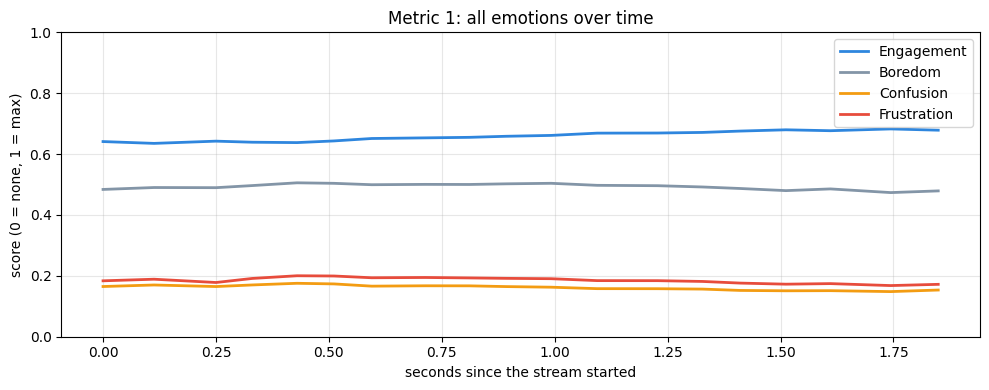

In [46]:
if score_log:
    seconds = np.array([logged_time for logged_time, _ in score_log])-score_log[0][0]
    over_time = np.stack([logged_scores for _, logged_scores in score_log])
    x_label = 'seconds since the stream started'
elif sample_scores is not None:
    over_time = sample_scores
    seconds = np.arange(len(over_time))*VIDEO_WINDOW_S
    x_label = f'seconds into the video (one point per {VIDEO_WINDOW_S:g} s window)'
else:
    over_time = None

if over_time is None:
    print("Skipped: no data yet. Run the live stream (section 5) & press Stop, or set SAMPLE_VIDEO & run the single-video test.")
else:
    fig, ax = plt.subplots(figsize=(10, 4))
    for i, name in enumerate(NAMES):
        ax.plot(seconds, over_time[:, i], label=name, color=BAR_COLORS[i], linewidth=2)
    ax.set_ylim(0, 1)
    ax.set_xlabel(x_label)
    ax.set_ylabel('score (0 = none, 1 = max)')
    ax.set_title('Metric 1: all emotions over time' + ('  (UNTRAINED head: placeholder scores)' if DEMO_MODE else ''))
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3)
    finish_plot(fig, '1_emotions_over_time')

    SUMMARY['Session length (seconds)'] = round(float(seconds[-1]), 1)
    for i, name in enumerate(NAMES):
        SUMMARY[f'Mean {name} score (this session)'] = round(float(over_time[:, i].mean()), 3)

#### METRIC 2: MAE & RMSE  
MAE (mean absolute error): the average size of the gap between the predicted score & the true score, in score units (0 to 1)  
&nbsp;&nbsp;&nbsp;&nbsp;-ex: MAE 0.20 on Engagement = predictions are off by 0.20 on average (0.20 x 3 = 0.6 of one DAiSEE rating level)  
&nbsp;&nbsp;&nbsp;&nbsp;-lower is better, 0 is perfect (not gonna happen)  

RMSE (root mean squared error): like MAE, but each gap is squared BEFORE averaging, then square-rooted  
&nbsp;&nbsp;&nbsp;&nbsp;-squaring punishes big misses much more than small ones, so RMSE is never smaller than MAE  
&nbsp;&nbsp;&nbsp;&nbsp;-a big difference between RMSE & MAE means the model makes a few large errors  
&nbsp;&nbsp;&nbsp;&nbsp;-lower is better, 0 is perfect  

baseline: the error you'd get by always guessing the average training score, a good model will beat it  
&nbsp;&nbsp;&nbsp;&nbsp;-measured on the TEST split  

In [47]:
if true_scores is None:
    print("Skipped: needs a trained head & saved Test embeddings (DEMO_MODE off).")
else:
    errors = pred_scores-true_scores
    mae = np.abs(errors).mean(axis=0)
    rmse = np.sqrt((errors**2).mean(axis=0))

    baseline_errors = true_scores-training_average()
    baseline_mae = np.abs(baseline_errors).mean(axis=0)
    baseline_rmse = np.sqrt((baseline_errors**2).mean(axis=0))

    display(pd.DataFrame({'MAE': mae, 'MAE baseline': baseline_mae, 'RMSE': rmse, 'RMSE baseline': baseline_rmse}, index=NAMES).round(3))

    x = np.arange(len(NAMES))
    width = 0.38
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, model_values, baseline_values, title in [(axes[0], mae, baseline_mae, 'MAE (lower is better)'),
                                                     (axes[1], rmse, baseline_rmse, 'RMSE (lower is better)')]:
        ax.bar(x-width/2, model_values, width, label='model', color='#2e86de')
        ax.bar(x+width/2, baseline_values, width, label='always guess the average', color='#b2bec3')
        ax.set_xticks(x)
        ax.set_xticklabels(NAMES)
        ax.set_ylim(0, max(model_values.max(), baseline_values.max())*1.3)
        ax.set_ylabel('error (score units, 0 to 1)')
        ax.set_title(title)
        ax.legend(loc='upper left')
    fig.suptitle('Metric 2: MAE & RMSE per feeling (Test split)')
    finish_plot(fig, '2_mae_rmse')

    for i, name in enumerate(NAMES):
        SUMMARY[f'MAE - {name}'] = round(float(mae[i]), 3)
        SUMMARY[f'RMSE - {name}'] = round(float(rmse[i]), 3)
    SUMMARY['MAE (mean of the 4 feelings)'] = round(float(mae.mean()), 3)
    SUMMARY['RMSE (mean of the 4 feelings)'] = round(float(rmse.mean()), 3)

Skipped: needs a trained head & saved Test embeddings (DEMO_MODE off).


#### METRIC 3: accuracy, precision, recall, and F1
these need whole-number answers, so each 0-to-1 score is rounded back to a DAiSEE level (0, 1, 2 or 3), measured on the TEST split & shown two ways:  
&nbsp;&nbsp;&nbsp;&nbsp;-VIEW A, "exact level": did we predict the exact rating (0, 1, 2 or 3)?  
&nbsp;&nbsp;&nbsp;&nbsp;-VIEW B, "is it HIGH?": a yes/no question, is the rating at or above `HIGH_LEVEL`?

definitions (tp = true positives, fp = false positives, fn = false negatives, for one answer such as "level 2" or "high"):  
&nbsp;&nbsp;&nbsp;&nbsp;-accuracy = share of all clips answered correctly  
&nbsp;&nbsp;&nbsp;&nbsp;-precision = tp/(tp+fp) = when we SAY it's that answer, how often are we right? (low = lots of false alarms)  
&nbsp;&nbsp;&nbsp;&nbsp;-recall = tp/(tp+fn) = of the clips that REALLY are that answer, how many did we catch? (low = we miss them)  
&nbsp;&nbsp;&nbsp;&nbsp;-F1 = 2 x precision x recall/(precision+recall) = one number that is only high when BOTH precision & recall are high  
&nbsp;&nbsp;&nbsp;&nbsp;-all four go from 0 to 1, higher is better  
&nbsp;&nbsp;&nbsp;&nbsp;-view A: precision / recall / F1 are averaged over the levels that appear in the test labels (a "macro" average, every level counts equally)  
&nbsp;&nbsp;&nbsp;&nbsp;-view B: precision / recall / F1 are for the "high" answer only  

baseline accuracy: the accuracy you'd get by always guessing the most common answer  
&nbsp;&nbsp;&nbsp;&nbsp;-DAiSEE is very lopsided (most Confusion & Frustration ratings are 0), so a model's accuracy only means something if it beats this number  

In [48]:
if true_scores is None:
    print("Skipped: needs a trained head & saved Test embeddings (DEMO_MODE off).")
else:
    true_levels = np.rint(true_scores*MAX_RATING).astype(int)
    pred_levels = np.clip(np.rint(pred_scores*MAX_RATING), 0, MAX_RATING).astype(int)

    views = {
        f'View A: exact level (0 to {MAX_RATING})': (true_levels, pred_levels, list(range(MAX_RATING+1))),
        f'View B: is it HIGH (rating >= {HIGH_LEVEL})?': ((true_levels>=HIGH_LEVEL).astype(int), (pred_levels>=HIGH_LEVEL).astype(int), [1]),
    }
    metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1', 'Baseline accuracy']

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, (view_name, (true_labels, pred_labels, classes)) in zip(axes, views.items()):
        rows = []
        for i, name in enumerate(NAMES):
            accuracy, precision, recall, f1 = classification_scores(true_labels[:, i], pred_labels[:, i], classes)
            baseline_accuracy = float(np.bincount(true_labels[:, i]).max()/len(true_labels))
            rows.append([accuracy, precision, recall, f1, baseline_accuracy])
            if 'View B' in view_name:
                SUMMARY[f'HIGH accuracy - {name}'] = round(accuracy, 3)
                SUMMARY[f'HIGH precision - {name}'] = round(precision, 3)
                SUMMARY[f'HIGH recall - {name}'] = round(recall, 3)
                SUMMARY[f'HIGH F1 - {name}'] = round(f1, 3)
            else:
                SUMMARY[f'Level accuracy - {name}'] = round(accuracy, 3)
                SUMMARY[f'Level macro F1 - {name}'] = round(f1, 3)
        table = pd.DataFrame(rows, columns=metric_labels, index=NAMES).round(3)
        print(view_name)
        display(table)

        x = np.arange(len(NAMES))
        width = 0.16
        for k, metric in enumerate(metric_labels):
            ax.bar(x+(k-2)*width, table[metric].fillna(0), width, label=metric, color=METRIC_COLORS[k])
        ax.set_xticks(x)
        ax.set_xticklabels(NAMES)
        ax.set_ylim(0, 1.35)
        ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        ax.set_title(view_name)
        ax.legend(fontsize=8, loc='upper center', ncol=3)
    fig.suptitle('Metric 3: accuracy, precision, recall & F1 per feeling (Test split)')
    finish_plot(fig, '3_classification_metrics')

Skipped: needs a trained head & saved Test embeddings (DEMO_MODE off).


#### METRIC 4: Speed  
&nbsp;&nbsp;&nbsp;&nbsp;-achieved fps = frames actually scored per second of the live session, capped by `SEND_FPS`
&nbsp;&nbsp;&nbsp;&nbsp;-head throughput = how many whole clips/second the head alone can score from saved embeddings (a speed test of the trained part, not the CNN)  
&nbsp;&nbsp;&nbsp;&nbsp;-window time (ms) = time to score one `VIDEO_FRAMES_PER_WINDOW`-frame window of a recorded video, from face finding to the 4 scores  

the goal for a smooth live demo is achieved fps close to `SEND_FPS`  

Live latency: mean 19.9 ms, median 18.5 ms, 95th percentile 25.1 ms
Max possible fps 50.2 | achieved fps 9.7 | target fps (SEND_FPS) 15


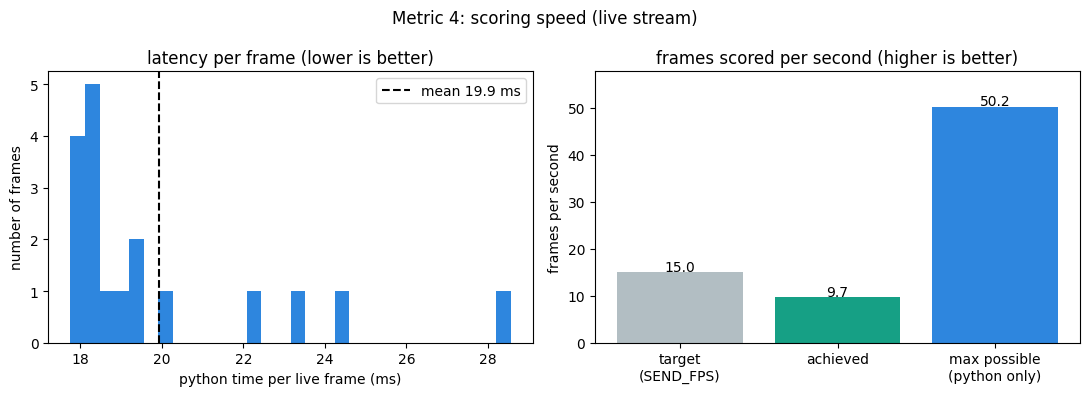

In [49]:
if head_clips_per_sec is not None:
    print(f"Head throughput: {head_clips_per_sec:,.0f} clips/second (from saved embeddings)")
    SUMMARY['Head throughput (clips/second)'] = round(head_clips_per_sec)

if SAMPLE_VIDEO and os.path.exists(SAMPLE_VIDEO):
    window_frames = read_frames(SAMPLE_VIDEO, VIDEO_FRAMES_PER_WINDOW)
    scorer.score_frames(window_frames)
    window_times = []
    for _ in range(10):
        start = time.perf_counter()
        scorer.score_frames(window_frames)
        window_times.append((time.perf_counter()-start)*1000)
    print(f"Recorded-video window ({VIDEO_FRAMES_PER_WINDOW} frames): {np.mean(window_times):.0f} ms")
    SUMMARY['Recorded-video window scoring time (ms)'] = round(float(np.mean(window_times)))

if len(LIVE['latency_ms'])<2:
    print("No live data yet: run the live stream (section 5), press Stop, then run this cell again for the latency & fps graph.")
else:
    latency = np.array(LIVE['latency_ms'])
    steady_latency = latency[1:]
    max_fps = 1000/steady_latency.mean()
    logged_times = np.array([logged_time for logged_time, _ in score_log])
    achieved_fps = (len(logged_times)-1)/(logged_times[-1]-logged_times[0])

    print(f"Live latency: mean {steady_latency.mean():.1f} ms, median {np.median(steady_latency):.1f} ms, 95th percentile {np.percentile(steady_latency, 95):.1f} ms")
    print(f"Max possible fps {max_fps:.1f} | achieved fps {achieved_fps:.1f} | target fps (SEND_FPS) {SEND_FPS}")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(steady_latency, bins=30, color='#2e86de')
    axes[0].axvline(steady_latency.mean(), color='k', linestyle='--', label=f'mean {steady_latency.mean():.1f} ms')
    axes[0].set_xlabel('python time per live frame (ms)')
    axes[0].set_ylabel('number of frames')
    axes[0].set_title('latency per frame (lower is better)')
    axes[0].legend()
    labels = ['target\n(SEND_FPS)', 'achieved', 'max possible\n(python only)']
    values = [SEND_FPS, achieved_fps, max_fps]
    bars = axes[1].bar(labels, values, color=['#b2bec3', '#16a085', '#2e86de'])
    for bar, value in zip(bars, values):
        axes[1].text(bar.get_x()+bar.get_width()/2, value+0.3, f"{value:.1f}", ha='center')
    axes[1].set_ylim(0, max(values)*1.15)
    axes[1].set_ylabel('frames per second')
    axes[1].set_title('frames scored per second (higher is better)')
    fig.suptitle('Metric 4: scoring speed (live stream)')
    finish_plot(fig, '4_scoring_speed')

    SUMMARY['Live latency per frame (ms, mean)'] = round(float(steady_latency.mean()), 1)
    SUMMARY['Live latency per frame (ms, 95th percentile)'] = round(float(np.percentile(steady_latency, 95)), 1)
    SUMMARY['Live fps achieved'] = round(float(achieved_fps), 1)
    SUMMARY['Live fps max possible (python only)'] = round(float(max_fps), 1)

#### SECTION 5C: Results  
&nbsp;&nbsp;&nbsp;&nbsp;-after pressing Stop in the live panel (& running the metrics cells), run this cell  
&nbsp;&nbsp;&nbsp;&nbsp;-every scored picture was logged w/ a timestamp which averages the log over blocks of `EXPORT_WINDOW_S` seconds & returns the (T, 4) array (columns = `NAMES`) that the GRU needs  
&nbsp;&nbsp;&nbsp;&nbsp;-running the stream again keeps adding to the same log, so run `clear_live_log()` between separate recordings  

In [50]:
def export_windows(window_s=EXPORT_WINDOW_S):
    if not score_log:
        return np.zeros((0, 4), np.float32)
    times = np.array([logged_time for logged_time, _ in score_log])
    all_scores = np.stack([logged_scores for _, logged_scores in score_log])
    block_number = ((times-times[0])//window_s).astype(int)
    rows = [all_scores[block_number==b].mean(0)
            for b in range(block_number.max()+1)
            if (block_number==b).any()]
    return np.stack(rows).astype(np.float32)


scores = export_windows()
print(scores.shape)
print(scores.round(3))

(1, 4)
[[0.659 0.493 0.162 0.185]]
